In [12]:
"""
Weather Prediction Pipeline - Ca Mau
Predict tempmax of next day using Ridge & LightGBM
Data source: Visual Crossing (10 years)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb


In [13]:

# ─────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────
def load_data(filepath: str) -> pd.DataFrame:
    df = pd.read_csv(filepath)
    df['datetime'] = pd.to_datetime(df['datetime'])
    df = df.sort_values('datetime').reset_index(drop=True)
    print(f"✅ Loaded: {df.shape[0]} rows, {df.shape[1]} cols")
    print(f"   Range: {df['datetime'].min().date()} → {df['datetime'].max().date()}")
    return df



In [14]:

# ─────────────────────────────────────────
# 2. PREPROCESSING
# ─────────────────────────────────────────
def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    # Columns to keep
    keep_cols = [
        'datetime',
        'tempmax', 'tempmin', 'temp',
        'feelslikemax', 'feelslikemin', 'feelslike',
        'dew', 'humidity',
        'precip', 'precipprob',
        'windspeed', 'windgust',
        'sealevelpressure', 'cloudcover',
        'solarradiation', 'solarenergy', 'uvindex',
        'sunrise', 'sunset'
    ]
    # Only keep columns that exist
    keep_cols = [c for c in keep_cols if c in df.columns]
    df = df[keep_cols].copy()

    # Drop Ca Mau irrelevant columns
    for col in ['snow', 'snowdepth', 'severerisk']:
        if col in df.columns:
            df.drop(columns=[col], inplace=True)

    # Fill missing values
    temp_cols = ['tempmax','tempmin','temp','dew','humidity','sealevelpressure',
                 'feelslikemax','feelslikemin','feelslike']
    temp_cols = [c for c in temp_cols if c in df.columns]
    df[temp_cols] = df[temp_cols].interpolate(method='linear')

    fill_zero = ['precip','precipprob','windgust','cloudcover']
    fill_zero = [c for c in fill_zero if c in df.columns]
    df[fill_zero] = df[fill_zero].fillna(0)

    print(f"✅ Preprocessing done. Missing: {df.isnull().sum().sum()} values remaining")
    return df


In [15]:


# ─────────────────────────────────────────
# 3. FEATURE ENGINEERING
# ─────────────────────────────────────────
def feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    # Time features
    df['month']      = df['datetime'].dt.month
    df['dayofyear']  = df['datetime'].dt.dayofyear
    df['sin_day']    = np.sin(2 * np.pi * df['dayofyear'] / 365)
    df['cos_day']    = np.cos(2 * np.pi * df['dayofyear'] / 365)
    df['sin_month']  = np.sin(2 * np.pi * df['month'] / 12)
    df['cos_month']  = np.cos(2 * np.pi * df['month'] / 12)

    # Ca Mau seasons
    df['is_rainy_season'] = df['month'].isin([5,6,7,8,9,10]).astype(int)
    df['is_peak_rain']    = df['month'].isin([7,8,9]).astype(int)
    df['is_dry_peak']     = df['month'].isin([2,3,4]).astype(int)

    # Derived features
    df['temp_range']      = df['tempmax'] - df['tempmin']
    df['pressure_change'] = df['sealevelpressure'] - df['sealevelpressure'].shift(1)
    df['tempmax_diff1']   = df['tempmax'] - df['tempmax'].shift(1)

    if 'sunrise' in df.columns and 'sunset' in df.columns:
        df['day_length'] = (
            pd.to_datetime(df['sunset']) - pd.to_datetime(df['sunrise'])
        ).dt.seconds / 3600
        df.drop(columns=['sunrise','sunset'], inplace=True)

    if 'solarradiation' in df.columns and 'cloudcover' in df.columns:
        df['solar_cloud'] = df['solarradiation'] * (1 - df['cloudcover'] / 100)

    if 'temp' in df.columns and 'humidity' in df.columns:
        df['heat_index'] = df['temp'] * df['humidity'] / 100

    # Lag features
    lag_cols = {
        'tempmax': [1, 2, 3],
        'tempmin': [1],
        'temp':    [1, 2],
        'humidity': [1, 2],
        'sealevelpressure': [1, 2],
        'precip':  [1],
        'cloudcover': [1],
        'dew':     [1],
    }
    for col, lags in lag_cols.items():
        if col in df.columns:
            for lag in lags:
                df[f'{col}_lag{lag}'] = df[col].shift(lag)

    # Rolling statistics
    df['tempmax_roll3'] = df['tempmax'].shift(1).rolling(3).mean()
    df['tempmax_roll7'] = df['tempmax'].shift(1).rolling(7).mean()
    df['temp_std3']     = df['temp'].shift(1).rolling(3).std()
    df['precip_roll7']  = df['precip'].shift(1).rolling(7).sum()

    # Target: tempmax of NEXT day
    df['target'] = df['tempmax'].shift(-1)

    # Drop NaN rows from lag/target
    df.dropna(inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"✅ Feature engineering done. Shape: {df.shape}")
    return df


In [16]:


# ─────────────────────────────────────────
# 4. TRAIN / VAL / TEST SPLIT
# ─────────────────────────────────────────
def split_data(df: pd.DataFrame):
    train = df[df['datetime'] < '2024-01-01']
    val   = df[(df['datetime'] >= '2024-01-01') & (df['datetime'] < '2025-01-01')]
    test  = df[df['datetime'] >= '2025-01-01']

    drop_cols = ['datetime', 'target']
    feature_cols = [c for c in df.columns if c not in drop_cols]

    X_train, y_train = train[feature_cols], train['target']
    X_val,   y_val   = val[feature_cols],   val['target']
    X_test,  y_test  = test[feature_cols],  test['target']

    print(f"✅ Split — Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")
    return X_train, y_train, X_val, y_val, X_test, y_test, feature_cols


In [17]:


# ─────────────────────────────────────────
# 5. METRICS
# ─────────────────────────────────────────
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"  [{name}] MAE={mae:.3f}°C | RMSE={rmse:.3f}°C | R²={r2:.4f}")
    return {'name': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}



In [18]:

# ─────────────────────────────────────────
# 6. BASELINE (naive lag-1)
# ─────────────────────────────────────────
def baseline(y_true, X):
    y_pred = X['tempmax'].values
    return evaluate("Baseline (lag1)", y_true, y_pred)



In [19]:

# ─────────────────────────────────────────
# 7. RIDGE REGRESSION
# ─────────────────────────────────────────
def train_ridge(X_train, y_train, X_val, y_val, X_test, y_test):
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s   = scaler.transform(X_val)
    X_test_s  = scaler.transform(X_test)

    best_alpha, best_rmse, best_model = None, np.inf, None
    for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
        m = Ridge(alpha=alpha)
        m.fit(X_train_s, y_train)
        rmse = np.sqrt(mean_squared_error(y_val, m.predict(X_val_s)))
        if rmse < best_rmse:
            best_rmse, best_alpha, best_model = rmse, alpha, m

    print(f"  Ridge best alpha={best_alpha} (val RMSE={best_rmse:.3f})")
    val_metrics  = evaluate("Ridge - Val",  y_val,  best_model.predict(X_val_s))
    test_metrics = evaluate("Ridge - Test", y_test, best_model.predict(X_test_s))
    return best_model, scaler, val_metrics, test_metrics



In [20]:

# ─────────────────────────────────────────
# 8. LIGHTGBM
# ─────────────────────────────────────────
def train_lgbm(X_train, y_train, X_val, y_val, X_test, y_test):
    model = lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=42,
        verbose=-1
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)]
    )
    print(f"  LightGBM best iteration: {model.best_iteration_}")
    val_metrics  = evaluate("LightGBM - Val",  y_val,  model.predict(X_val))
    test_metrics = evaluate("LightGBM - Test", y_test, model.predict(X_test))
    return model, val_metrics, test_metrics



In [21]:

# ─────────────────────────────────────────
# 9. PLOT RESULTS
# ─────────────────────────────────────────
def plot_results(df, X_test, y_test, ridge_model, ridge_scaler, lgbm_model, feature_cols, results):
    test_df = df[df['datetime'] >= '2025-01-01'].copy()
    dates   = test_df['datetime'].values

    ridge_pred = ridge_model.predict(ridge_scaler.transform(X_test))
    lgbm_pred  = lgbm_model.predict(X_test)
    naive_pred = X_test['tempmax_lag1'].values

    fig = plt.figure(figsize=(18, 14))
    fig.suptitle('Ca Mau Weather Prediction — tempmax next day', fontsize=15, fontweight='bold', y=0.98)
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

    # --- Plot 1: Predictions vs Actual (full test year) ---
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(dates, y_test.values, label='Actual', color='black', linewidth=1.5)
    ax1.plot(dates, lgbm_pred,    label='LightGBM', color='#2196F3', linewidth=1, alpha=0.85)
    ax1.plot(dates, ridge_pred,   label='Ridge',    color='#FF5722', linewidth=1, alpha=0.85, linestyle='--')
    ax1.set_title('Predictions vs Actual (Test Set 2025)')
    ax1.set_ylabel('Temperature (°C)')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # --- Plot 2: Residuals LightGBM ---
    ax2 = fig.add_subplot(gs[1, 0])
    residuals_lgbm = y_test.values - lgbm_pred
    ax2.plot(dates, residuals_lgbm, color='#2196F3', linewidth=0.8, alpha=0.7)
    ax2.axhline(0, color='black', linewidth=1)
    ax2.fill_between(dates, residuals_lgbm, 0, alpha=0.2, color='#2196F3')
    ax2.set_title('LightGBM Residuals')
    ax2.set_ylabel('Error (°C)')
    ax2.grid(alpha=0.3)

    # --- Plot 3: Residuals Ridge ---
    ax3 = fig.add_subplot(gs[1, 1])
    residuals_ridge = y_test.values - ridge_pred
    ax3.plot(dates, residuals_ridge, color='#FF5722', linewidth=0.8, alpha=0.7)
    ax3.axhline(0, color='black', linewidth=1)
    ax3.fill_between(dates, residuals_ridge, 0, alpha=0.2, color='#FF5722')
    ax3.set_title('Ridge Residuals')
    ax3.set_ylabel('Error (°C)')
    ax3.grid(alpha=0.3)

    # --- Plot 4: Metrics Comparison ---
    ax4 = fig.add_subplot(gs[2, 0])
    models  = ['Baseline\n(lag1)', 'Ridge', 'LightGBM']
    maes    = [results['baseline']['MAE'], results['ridge_test']['MAE'], results['lgbm_test']['MAE']]
    rmses   = [results['baseline']['RMSE'], results['ridge_test']['RMSE'], results['lgbm_test']['RMSE']]
    x = np.arange(len(models))
    w = 0.35
    bars1 = ax4.bar(x - w/2, maes,  w, label='MAE',  color=['#9E9E9E','#FF5722','#2196F3'], alpha=0.85)
    bars2 = ax4.bar(x + w/2, rmses, w, label='RMSE', color=['#9E9E9E','#FF5722','#2196F3'], alpha=0.5)
    for bar in bars1: ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2: ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
    ax4.set_title('Model Comparison (Test Set)')
    ax4.set_ylabel('°C')
    ax4.set_xticks(x); ax4.set_xticklabels(models)
    ax4.legend(); ax4.grid(alpha=0.3, axis='y')

    # --- Plot 5: Feature Importance (LightGBM top 15) ---
    ax5 = fig.add_subplot(gs[2, 1])
    importance = pd.Series(lgbm_model.feature_importances_, index=feature_cols)
    importance.nlargest(15).sort_values().plot(kind='barh', ax=ax5, color='#2196F3', alpha=0.8)
    ax5.set_title('LightGBM — Top 15 Feature Importance')
    ax5.set_xlabel('Importance')
    ax5.grid(alpha=0.3, axis='x')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig('ca_mau_weather_prediction_results.png', dpi=300)
    plt.show()
    plt.close()
    print("✅ Plot saved.")


In [23]:


# ─────────────────────────────────────────
# 10. MAIN
# ─────────────────────────────────────────

print("  CA MAU WEATHER PREDICTION PIPELINE")


df = load_data("CaMau_Weather.csv")
df = preprocess(df)
df = feature_engineering(df)

X_train, y_train, X_val, y_val, X_test, y_test, feature_cols = split_data(df)

results = {}

print("\n📊 BASELINE:")
results['baseline'] = baseline(y_test, X_test)


print("\n📊 RIDGE REGRESSION:")
ridge_model, ridge_scaler, ridge_val, ridge_test = train_ridge(
    X_train, y_train, X_val, y_val, X_test, y_test
)
results['ridge_val']  = ridge_val
results['ridge_test'] = ridge_test

print("\n📊 LIGHTGBM:")
lgbm_model, lgbm_val, lgbm_test = train_lgbm(
    X_train, y_train, X_val, y_val, X_test, y_test
)
results['lgbm_val']  = lgbm_val
results['lgbm_test'] = lgbm_test

print("\n" + "="*55)
print("  FINAL SUMMARY (Test Set)")
print("="*55)
print(f"  {'Model':<20} {'MAE':>8} {'RMSE':>8} {'R²':>8}")
print(f"  {'-'*44}")
for key in ['baseline', 'ridge_test', 'lgbm_test']:
    r = results[key]
    name = r['name'].replace(' - Test','').replace('Baseline (lag1)','Baseline')
    print(f"  {name:<20} {r['MAE']:>7.3f}°C {r['RMSE']:>7.3f}°C {r['R2']:>8.4f}")



  CA MAU WEATHER PREDICTION PIPELINE
✅ Loaded: 4018 rows, 33 cols
   Range: 2015-01-01 → 2025-12-31
✅ Preprocessing done. Missing: 0 values remaining
✅ Feature engineering done. Shape: (4010, 51)
✅ Split — Train: 3280 | Val: 366 | Test: 364

📊 BASELINE:
  [Baseline (lag1)] MAE=0.879°C | RMSE=1.144°C | R²=0.3055

📊 RIDGE REGRESSION:
  Ridge best alpha=1 (val RMSE=0.950)
  [Ridge - Val] MAE=0.739°C | RMSE=0.950°C | R²=0.7193
  [Ridge - Test] MAE=0.749°C | RMSE=0.962°C | R²=0.5093

📊 LIGHTGBM:
  LightGBM best iteration: 64
  [LightGBM - Val] MAE=0.754°C | RMSE=0.970°C | R²=0.7073
  [LightGBM - Test] MAE=0.771°C | RMSE=0.967°C | R²=0.5041

  FINAL SUMMARY (Test Set)
  Model                     MAE     RMSE       R²
  --------------------------------------------
  Baseline               0.879°C   1.144°C   0.3055
  Ridge                  0.749°C   0.962°C   0.5093
  LightGBM               0.771°C   0.967°C   0.5041



📈 Generating plots...


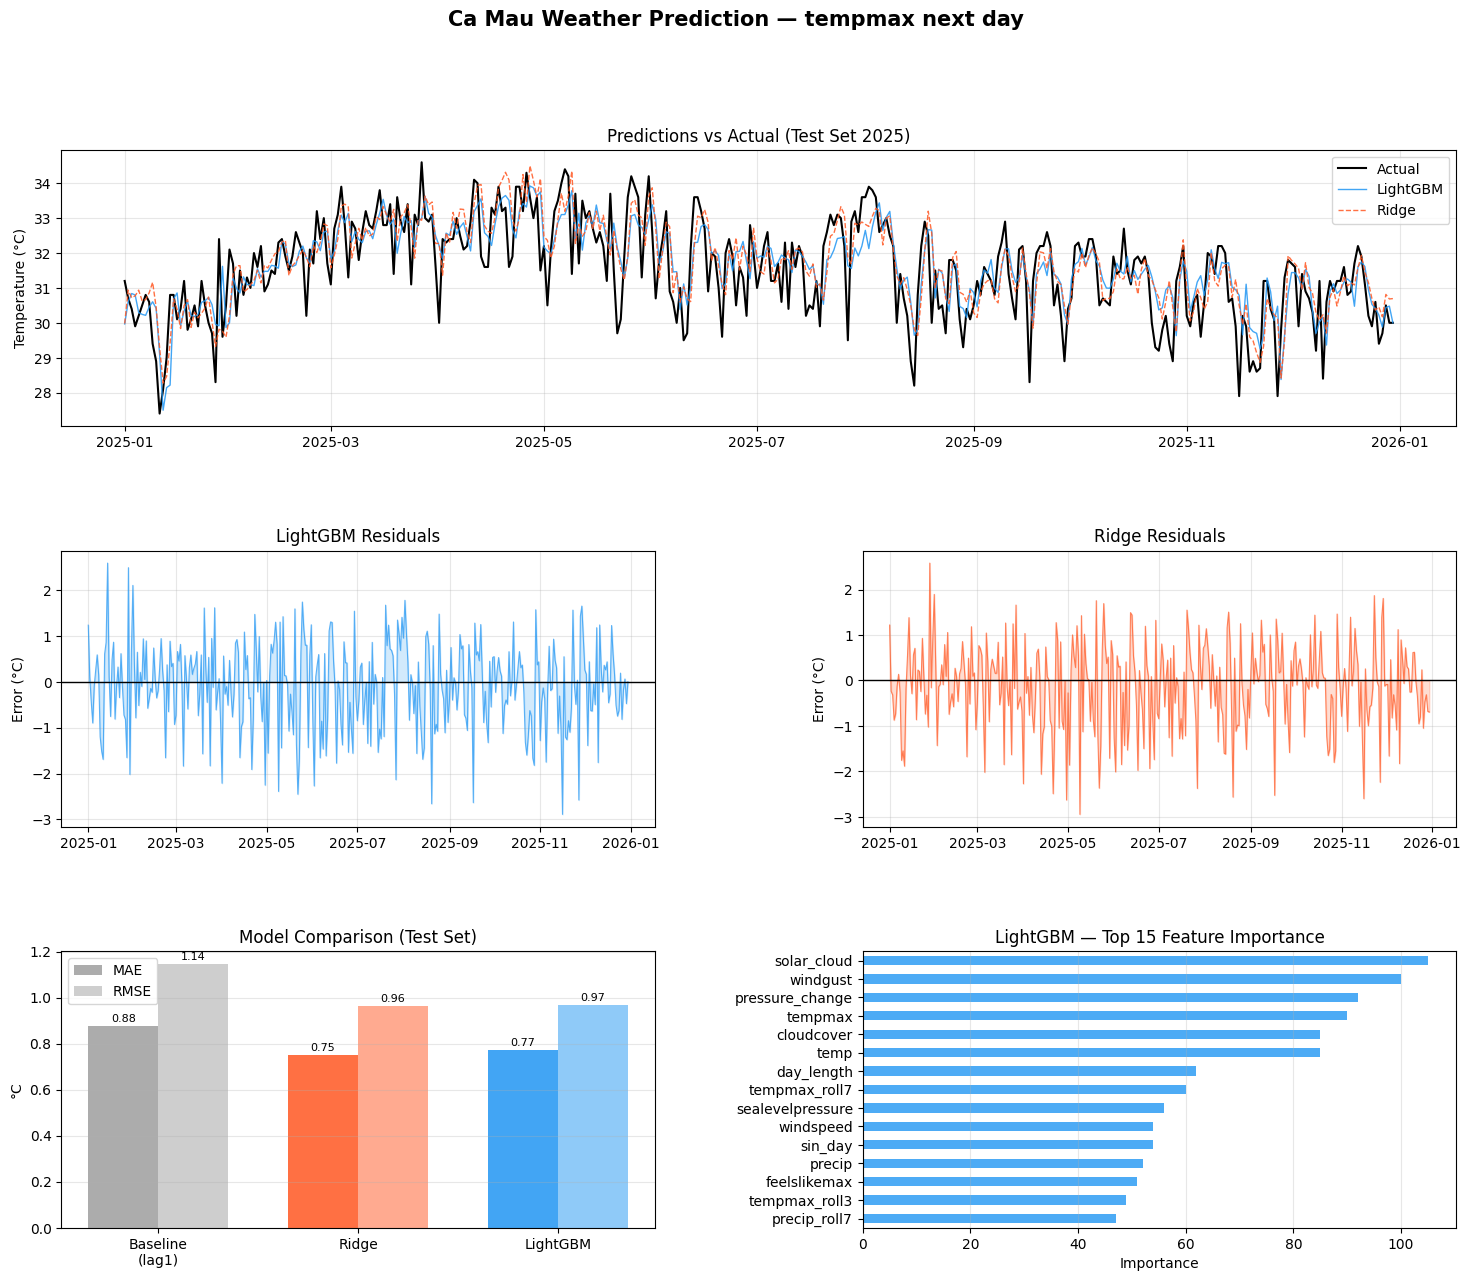

✅ Plot saved.

✅ Done! Output saved to weather_prediction_results.png


In [ ]:


print("\n📈 Generating plots...")
plot_results(df, X_test, y_test, ridge_model, ridge_scaler, lgbm_model, feature_cols, results)

print("\n✅ Done! Output saved to weather_prediction_results.png")